
<font size=15 ><b> Proyecto derivados

</b></font>
 
 


---

·&nbsp; **Diego Marquez Franco** &nbsp;

·&nbsp; **Emiliano Aguilar Navarrete** &nbsp;



# Forwards


## 1. Forward: valuación por ausencia de arbitraje

Un **forward largo** es un contrato para comprar un activo en $T$ a un precio de entrega $K$. Su payoff es

$$
X_T=S_T-K.
$$

### Sin dividendos

Consideremos dos portafolios:

- **A:** Un forward largo $+$ $KB(t,T)$ en efectivo.
- **B:** Una unidad del subyacente.

Al vencimiento ambos valen $S_T$. Por ausencia de arbitraje,

$$
f_t+KB(t,T)=S_t.
$$

Por tanto, el valor del contrato y el precio forward son

$$
\boxed{f_t=S_t-KB(t,T)}
\qquad
\boxed{F_t=\frac{S_t}{B(t,T)}}.
$$

Si $r$ es constante, $B(t,T)=e^{-r(T-t)}$ y

$$
\boxed{F_t=S_te^{r(T-t)}}.
$$

###  Con dividendos conocidos

Si el activo paga dividendos $D_i$ antes de $T$, su valor presente es

$$
I_t=\sum_i D_iB(t,t_i).
$$

Comparamos:

- **A:** Un forward largo $+$ $KB(t,T)$ en efectivo $+$ un instrumento que paga los dividendos $D_i$.
- **B:** Una unidad del subyacente, incluyendo sus dividendos.

Ambos producen los mismos flujos, por lo que

$$
f_t+KB(t,T)+I_t=S_t.
$$

Así,

$$
\boxed{f_t=S_t-I_t-KB(t,T)}
\qquad
\boxed{F_t=\frac{S_t-I_t}{B(t,T)}}.
$$

### Con dividendos continuos

Supongamos que el activo paga dividendos a una tasa proporcional constante $\delta$.

Comparamos:

- **A:** Un forward largo $+$ $KB(t,T)$ en efectivo.
- **B:** $e^{-\delta(T-t)}$ unidades del subyacente, reinvirtiendo continuamente sus dividendos.

En $T$, ambos portafolios entregan una unidad del activo. Entonces,

$$
f_t+KB(t,T)=S_te^{-\delta(T-t)}.
$$

Por tanto,

$$
\boxed{f_t=S_te^{-\delta(T-t)}-KB(t,T)}
$$

y, si $r$ es constante,

$$
\boxed{F_t=S_te^{(r-\delta)(T-t)}}.
$$


In [45]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

def forward(S, K, T, r, t=0, tipo="sin", dividendos=(), delta=0):
    """
    Valuación de un forward largo por ausencia de arbitraje.

    tipo: 'sin', 'discretos', 'continuos'
    dividendos: [(fecha, monto), ...]
    delta: tasa continua de dividendos
    """

    if not all(np.isfinite(x) for x in (S, K, T, r, t, delta)):
        raise ValueError("Los parámetros deben ser finitos.")
    if S <= 0 or K < 0 or T <= t:
        raise ValueError("Se requiere S > 0, K >= 0 y T > t.")

    tau = T - t
    B = np.exp(-r * tau)
    I = 0

    if tipo == "sin":
        S_ajustado = S

    elif tipo == "discretos":
        for fecha, monto in dividendos:
            if not np.isfinite(fecha) or not np.isfinite(monto) or monto < 0:
                raise ValueError("Dividendo inválido.")
            if t < fecha < T:
                I += monto * np.exp(-r * (fecha - t))
        S_ajustado = S - I

    elif tipo == "continuos":
        if delta < 0:
            raise ValueError("La tasa de dividendos debe ser no negativa.")
        S_ajustado = S * np.exp(-delta * tau)

    else:
        raise ValueError("Tipo de dividendos no reconocido.")

    if S_ajustado <= 0:
        raise ValueError("El precio ajustado debe ser positivo.")

    F = S_ajustado / B
    f = S_ajustado - K * B

    return {
        "F": F,                    # Precio forward justo
        "f": f,                    # Valor del contrato
        "B": B,                    # Factor de descuento
        "S_ajustado": S_ajustado,  # Posición replicante en activo
        "PV_K": K * B,             # Valor presente del pago
        "I": I
    }


In [46]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def mostrar_forward(S, K, T, r, t=0, tipo="sin",
                    dividendos=(), delta=0):

    # Valuación con el modelo anterior
    res = forward(S, K, T, r, t, tipo, dividendos, delta)

    F, f = res["F"], res["f"]
    B, I = res["B"], res["I"]
    S_adj = res["S_ajustado"]
    tau = T - t
    prestamo = K * B



    display(Markdown(rf"""
## Forward Valuation

| Spot $S_t$ | Entrega $K$ | Tasa $r$ | Madurez |
|---:|---:|---:|---:|
| {S:.2f} | {K:.2f} | {r:.2%} | {tau:.2f} años |

| Resultado | Valor |
|---|---:|
| Factor de descuento $B(t,T)$ | {B:.6f} |
| Precio forward $F_t$ | **{F:.4f}** |
| Valor del contrato $f_t$ | **{f:.4f}** |

**Valuación por ausencia de arbitraje**

$$
f_t=S_t^{{adj}}-KB(t,T)
$$

$$
f_t={S_adj:.4f}-{prestamo:.4f}
=\boxed{{{f:.4f}}}
$$
"""))
    # 2. REPLICACION SEGUN DIVIDENDOS
    

    if tipo == "sin":
        explicacion = rf"""
### Replicación — Sin dividendos

1. Compramos **1 unidad del subyacente** por {S:.4f}.
2. Pedimos prestados **{prestamo:.4f}** a una tasa continua de {r:.2%}.
3. Al vencimiento, devolvemos:

$$
{prestamo:.4f}e^{{{r:.4f}({tau:.4f})}}={K:.4f}
$$

El valor inicial del portafolio es

$$
V_t={S:.4f}-{prestamo:.4f}=\boxed{{{f:.4f}}}
$$
"""

    elif tipo == "discretos":
        deuda = prestamo + I
        explicacion = rf"""
### Replicación — Dividendos conocidos

1. Compramos **1 unidad del subyacente** por {S:.4f}.
2. Pedimos prestados **{deuda:.4f}** a una tasa continua de {r:.2%}.
3. Usamos los dividendos recibidos para amortizar la parte de la deuda que los financia.
4. Al vencimiento queda una deuda de **{K:.4f}**.

El préstamo inicial es

$$
\underbrace{{{prestamo:.4f}}}_{{\text{{Pago de entrega}}}}
+
\underbrace{{{I:.4f}}}_{{\text{{VP dividendos}}}}
={deuda:.4f}
$$

El valor inicial del portafolio es

$$
V_t={S:.4f}-{deuda:.4f}=\boxed{{{f:.4f}}}
$$
"""

    elif tipo == "continuos":
        unidades = np.exp(-delta * tau)
        explicacion = rf"""
### Replicación — Dividendos continuos

Tasa continua de dividendos: **{delta:.2%}**.

1. Compramos **{unidades:.6f} unidades** del subyacente.
2. El costo de esta posición es **{S_adj:.4f}**.
3. Pedimos prestados **{prestamo:.4f}** a una tasa continua de {r:.2%}.
4. Reinvertimos todos los dividendos en el subyacente.

Al vencimiento tendremos una unidad:

$$
{unidades:.6f}e^{{{delta:.4f}({tau:.4f})}}=1
$$

Y nuestra deuda será

$$
{prestamo:.4f}e^{{{r:.4f}({tau:.4f})}}={K:.4f}
$$

El valor inicial del portafolio es

$$
V_t={S_adj:.4f}-{prestamo:.4f}
=\boxed{{{f:.4f}}}
$$
"""

    display(Markdown(explicacion))

    display(Markdown(r"""
**Replicación terminal**

Independientemente del comportamiento del subyacente,

$$
\boxed{V_T=S_T-K=X_T}
$$

El portafolio replica exactamente el payoff del forward.
"""))

    # 3. PAYOFF Y REPLICACION

    ST = np.linspace(max(0, S * 0.4), max(1.6*S, 1.3*K), 400)
    payoff = ST - K
    replicacion = ST - K

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.fill_between(ST, 0, payoff, where=payoff >= 0,
                    color="#16a34a", alpha=0.18)

    ax.fill_between(ST, 0, payoff, where=payoff < 0,
                    color="#dc2626", alpha=0.18)

    ax.plot(ST, payoff, color="#2563eb", lw=2.5,
            label="Forward largo")

    ax.plot(ST, replicacion, "--", color="#f59e0b",
            lw=1.5, label="Portafolio replicante")

    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(K, color="gray", linestyle=":", label=f"K = {K}")

    ax.set(
        title="Forward — Payoff y Replicación",
        xlabel="Precio terminal $S_T$",
        ylabel="Valor terminal"
    )

    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

    # Comprobación numérica
    assert np.allclose(payoff, replicacion)
    assert np.isclose(f, S_adj - K*B)

    return res



## Forward Valuation

| Spot $S_t$ | Entrega $K$ | Tasa $r$ | Madurez |
|---:|---:|---:|---:|
| 100.00 | 105.00 | 5.00% | 1.00 años |

| Resultado | Valor |
|---|---:|
| Factor de descuento $B(t,T)$ | 0.951229 |
| Precio forward $F_t$ | **102.0201** |
| Valor del contrato $f_t$ | **-2.8345** |

**Valuación por ausencia de arbitraje**

$$
f_t=S_t^{adj}-KB(t,T)
$$

$$
f_t=97.0446-99.8791
=\boxed{-2.8345}
$$



### Replicación — Dividendos continuos

Tasa continua de dividendos: **3.00%**.

1. Compramos **0.970446 unidades** del subyacente.
2. El costo de esta posición es **97.0446**.
3. Pedimos prestados **99.8791** a una tasa continua de 5.00%.
4. Reinvertimos todos los dividendos en el subyacente.

Al vencimiento tendremos una unidad:

$$
0.970446e^{0.0300(1.0000)}=1
$$

Y nuestra deuda será

$$
99.8791e^{0.0500(1.0000)}=105.0000
$$

El valor inicial del portafolio es

$$
V_t=97.0446-99.8791
=\boxed{-2.8345}
$$



**Replicación terminal**

Independientemente del comportamiento del subyacente,

$$
\boxed{V_T=S_T-K=X_T}
$$

El portafolio replica exactamente el payoff del forward.


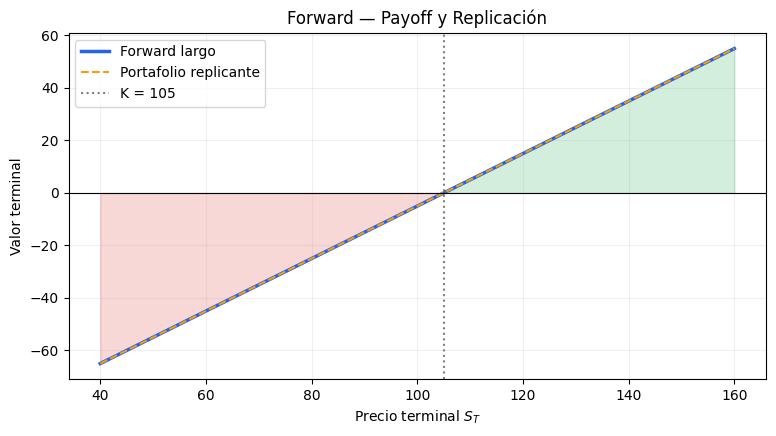

In [47]:

# Parámetros
S = 100
K = 105
T = 1
r = 0.05

# Dividendos: "sin", "discretos", "continuos"
tipo = "continuos"
delta = 0.03
dividendos = [(0.5, 2)]

# Ejecutar
resultado = mostrar_forward(
    S=S,
    K=K,
    T=T,
    r=r,
    tipo=tipo,
    delta=delta,
    dividendos=dividendos
)


# Modelo binomial: no arbitraje, valuación y replicación



###  Un periodo

Sea $S_0>0$ el precio inicial del subyacente, que en $T$ puede tomar dos valores:

$$
S_u=uS_0,\qquad S_d=dS_0,\qquad u>d>0.
$$

Un derivado con payoff $X=g(S_T)$ paga $X_u$ si el activo sube y $X_d$ si baja.

Construimos un **portafolio replicante** con $\alpha$ unidades del subyacente y $\beta$ pesos invertidos en la cuenta bancaria:

$$
V_0=\alpha S_0+\beta.
$$

Para replicar el payoff en ambos estados:

$$
\begin{cases}
\alpha S_u+\dfrac{\beta}{D}=X_u,\\[6pt]
\alpha S_d+\dfrac{\beta}{D}=X_d,
\end{cases}
\qquad D=B(0,T).
$$

Resolviendo el sistema:

$$
\boxed{\alpha=\frac{X_u-X_d}{S_u-S_d}},
\qquad
\boxed{\beta=D(X_u-\alpha S_u)}.
$$

Por **ausencia de arbitraje**, el precio del derivado es el costo de su replicación:

$$
\boxed{V_0=\alpha S_0+\beta}.
$$

### Probabilidad neutral al riesgo

Definimos

$$
\boxed{q=\frac{B(0,T)^{-1}-d}{u-d}}.
$$

Sustituyendo $\alpha$ y $\beta$ en $V_0$, obtenemos

$$
\boxed{V_0=B(0,T)\left[qX_u+(1-q)X_d\right]}.
$$

La condición estricta de ausencia de arbitraje es

$$
\boxed{0<q<1\iff d<B(0,T)^{-1}<u}.
$$

 $q$ es la probabilidad neutral al riesgo, distinta de la probabilidad física $p$. El precio se obtiene por replicación y no depende de $p$.

### Modelo de $n$ periodos

Dividimos $[0,T]$ en $n$ periodos de longitud $\Delta t=T/n$. Suponemos $u$, $d$ y la tasa $r$ constantes.


$$
\boxed{S_{i,j}=S_0u^jd^{\,i-j}},
\qquad 0\leq j\leq i.
$$

El factor de descuento y la probabilidad neutral al riesgo **por periodo** son

$$
\boxed{B(0,t)=e^{-r\Delta t}},
\qquad
\boxed{q=\frac{e^{r\Delta t}-d}{u-d}}.
$$

En el vencimiento, los valores del derivado son

$$
V_{n,j}=g(S_0u^jd^{n-j}).
$$

Calculamos el precio **hacia atrás**, desde los nodos terminales:

$$
\boxed{
V=B(0,\Delta t)\left[qV_{u}+(1-q)V_{d}\right].
}
$$

En cada nodo también podemos construir la cobertura:

$$
\boxed{
\alpha_{n}=
\frac{V_{u}-V_{d}}
{S_{u}-S_{d}}
}
$$

$$
\boxed{
\beta_n=B\left(V_{u}
-\alpha S_{u}\right).
}
$$

Para una **opción europea cuyo payoff depende solo de $S_T$**, la fórmula general es

$$
\boxed{
V_0=e^{-rT}\sum_{j=0}^{n}
\binom{n}{j}q^j(1-q)^{n-j}
g(S_0u^jd^{n-j})
}.
$$

Esta fórmula representa la esperanza descontada del payoff bajo la medida neutral al riesgo:

$$
\boxed{V_0=e^{-rT}\mathbb{E}^{\mathbb{Q}}[g(S_T)]}.
$$



In [1]:

import numpy as np
import matplotlib.pyplot as plt
from math import comb
from IPython.display import display, Markdown


def binomial(S0, K, T, n, r, tipo="call", u=None, d=None, sigma=None):

    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n debe ser un entero positivo.")
    if not np.all(np.isfinite([S0, K, T, r])) or S0 <= 0 or K < 0 or T <= 0:
        raise ValueError("Parámetros inválidos.")

    dt = T / n
    B = np.exp(-r * dt)

    if sigma is not None:
        if u is not None or d is not None or not np.isfinite(sigma) or sigma <= 0:
            raise ValueError("Proporciona sigma > 0 o los factores u, d.")
        u = np.exp(sigma * np.sqrt(dt))
        d = 1 / u

    if u is None or d is None or not np.all(np.isfinite([u, d])) or not (0 < d < u):
        raise ValueError("Se requiere 0 < d < u.")

    q = (1 / B - d) / (u - d)

    if not 0 < q < 1:
        raise ValueError("No se cumple la condición de no arbitraje.")

    def payoff(s):
        s = np.asarray(s)
        if tipo == "call":
            return np.maximum(s - K, 0)
        if tipo == "put":
            return np.maximum(K - s, 0)
        if tipo == "forward":
            return s - K
        if tipo == "digital":
            return (s > K).astype(float)
        raise ValueError("Tipo no reconocido.")

    S = [
        S0 * u**np.arange(i + 1) * d**(i - np.arange(i + 1))
        for i in range(n + 1)
    ]

    if not all(np.all(np.isfinite(s)) for s in S):
        raise ValueError("El árbol contiene valores no finitos.")

    V = [None] * (n + 1)
    alpha = [None] * n
    beta = [None] * n

    V[n] = payoff(S[n])

    for i in range(n - 1, -1, -1):
        Vu, Vd = V[i+1][1:], V[i+1][:-1]

        V[i] = B * (q * Vu + (1-q) * Vd)
        alpha[i] = (Vu - Vd) / (S[i+1][1:] - S[i+1][:-1])
        beta[i] = B * (Vu - alpha[i] * S[i+1][1:])

        if not np.allclose(V[i], alpha[i]*S[i] + beta[i]):
            raise ArithmeticError("Error de replicación.")

    precio = V[0][0]

    precio_suma = B**n * sum(
        comb(n, j) * q**j * (1-q)**(n-j) * V[n][j]
        for j in range(n+1)
    )

    if not np.isclose(precio, precio_suma):
        raise ArithmeticError("Los métodos de valuación no coinciden.")

    return dict(
        precio=precio, precio_suma=precio_suma,
        S=S, V=V, alpha=alpha, beta=beta,
        q=q, B=B, u=u, d=d,
        S0=S0, K=K, T=T, n=n, r=r,
        tipo=tipo, payoff=payoff
    )


def mostrar_binomial(m):

    S, V = m["S"], m["V"]
    q, B = m["q"], m["B"]
    a, b = m["alpha"][0][0], m["beta"][0][0]
    Vu, Vd = V[1][1], V[1][0]
    Su, Sd = S[1][1], S[1][0]

    display(Markdown(rf"""
### Valuación binomial — {m['tipo'].capitalize()}

$$
q=\frac{{B^{{-1}}-d}}{{u-d}}={q:.6f},
\qquad B={B:.6f}
$$

$$
V_0=B[qV_u+(1-q)V_d]
=\boxed{{{m['precio']:.6f}}}
$$

**Portafolio replicante inicial**

$$
\alpha=\frac{{V_u-V_d}}{{S_u-S_d}}
=\frac{{{Vu:.4f}-{Vd:.4f}}}{{{Su:.4f}-{Sd:.4f}}}
=\boxed{{{a:.6f}}}
$$

$$
\beta=B(V_u-\alpha S_u)=\boxed{{{b:.6f}}}
$$

$$
V_0=\alpha S_0+\beta
=({a:.6f})({m['S0']:.4f})+({b:.6f})
=\boxed{{{m['precio']:.6f}}}
$$

{'Se pide prestado' if b < 0 else 'Se invierte'} **{abs(b):.4f}** en la cuenta bancaria.

La posición inicial contiene **{abs(a):.4f}** unidades del subyacente
({'compradas' if a >= 0 else 'vendidas en corto'}).

Para $n>1$, la cartera se reajusta en cada nodo.
"""))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    niveles = min(m["n"], 4)

    for i in range(niveles + 1):
        for j in range(i + 1):
            x, y = i, 2*j-i

            if i < niveles:
                ax[0].plot([x, x+1], [y, y+1], color="gray", alpha=0.5)
                ax[0].plot([x, x+1], [y, y-1], color="gray", alpha=0.5)

            ax[0].scatter(x, y, color="steelblue", zorder=3)
            ax[0].annotate(
                f"S={S[i][j]:.2f}\nV={V[i][j]:.2f}",
                (x, y), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=8
            )

    ax[0].set_title(f"Árbol binomial (primeros {niveles} periodos)")
    ax[0].set_xlabel("Periodo")
    ax[0].set_xticks(range(niveles+1))
    ax[0].set_yticks([])
    ax[0].margins(y=0.3)

    ST = np.linspace(
        max(0, m["S0"]*0.4),
        max(m["S0"]*1.6, m["K"]*1.4, 1),
        400
    )
    pago = m["payoff"](ST)

    ax[1].plot(ST, pago, label="Payoff")
    ax[1].fill_between(ST, 0, pago, where=pago>=0,
                       color="green", alpha=0.15)
    ax[1].fill_between(ST, 0, pago, where=pago<0,
                       color="red", alpha=0.15)
    ax[1].axhline(0, color="black", linewidth=0.8)
    ax[1].axvline(m["K"], color="gray", linestyle="--")
    ax[1].set_title(f"Payoff — {m['tipo']}")
    ax[1].set_xlabel("$S_T$")
    ax[1].set_ylabel("$g(S_T)$")
    ax[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print(f"Precio por árbol: {m['precio']:.6f}")
    print(f"Precio por suma binomial: {m['precio_suma']:.6f}")



### Valuación binomial — Call

$$
q=\frac{B^{-1}-d}{u-d}=0.543777,
\qquad B=0.983471
$$

$$
V_0=B[qV_u+(1-q)V_d]
=\boxed{8.354284}
$$

**Portafolio replicante inicial**

$$
\alpha=\frac{V_u-V_d}{S_u-S_d}
=\frac{13.8844-2.0707}{112.2401-89.0947}
=\boxed{0.510414}
$$

$$
\beta=B(V_u-\alpha S_u)=\boxed{-42.687166}
$$

$$
V_0=\alpha S_0+\beta
=(0.510414)(100.0000)+(-42.687166)
=\boxed{8.354284}
$$

Se pide prestado **42.6872** en la cuenta bancaria.

La posición inicial contiene **0.5104** unidades del subyacente
(compradas).

Para $n>1$, la cartera se reajusta en cada nodo.


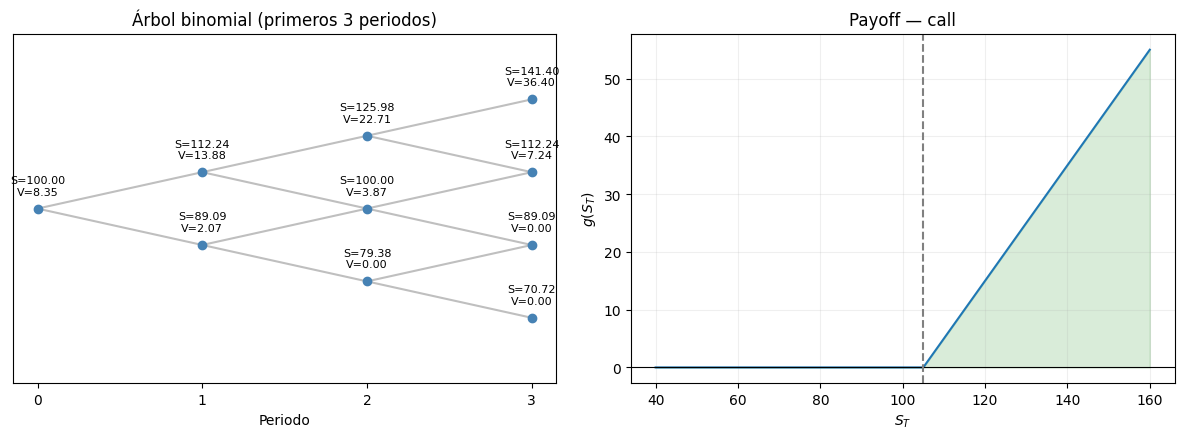

Precio por árbol: 8.354284
Precio por suma binomial: 8.354284


In [2]:

# Parámetros del modelo
S0 = 100
K = 105
T = 1
n = 3
r = 0.05
sigma = 0.20

# "call", "put", "forward", "digital"
tipo = "call"

# Valuar y visualizar
resultado = binomial(
    S0=S0,
    K=K,
    T=T,
    n=n,
    r=r,
    sigma=sigma,
    tipo=tipo
)

mostrar_binomial(resultado)



### Opciones digitales

Una **opción digital** paga una cantidad fija $A$ si se cumple cierta condición al vencimiento.

Para una digital call y una digital put:

$$
X_T^{call}=A\mathbf{1}_{\{S_T>K\}},
\qquad
X_T^{put}=A\mathbf{1}_{\{S_T<K\}}.
$$

Donde $\mathbf{1}$ es la función indicadora, que vale $1$ si la condición se cumple y $0$ en caso contrario.

**Valuación binomial**

Construimos el mismo árbol del subyacente:

$$
S_{i,j}=S_0u^jd^{i-j}.
$$

En los nodos terminales asignamos el payoff digital y calculamos hacia atrás:

$$
\boxed{V_{n}=B[qV_{u}+(1-q)V_{d}]}.
$$

Para una digital call de $n$ periodos:

$$
\boxed{
V_0=AB(0,T)^n\sum_{j=0}^{n}
\binom{n}{j}q^j(1-q)^{n-j}
\mathbf{1}_{\{S_0u^jd^{n-j}>K\}}
}.
$$

Es decir, su precio es el pago fijo multiplicado por la probabilidad neutral al riesgo de terminar dentro del dinero y descontado a valor presente.

### Opciones de barrera

Una **opción de barrera** depende del precio del subyacente y de si este alcanza un nivel $H$ durante la vida del contrato.

Existen cuatro tipos principales:

| Tipo | Condición |
|---|---|
| Up-and-out | Se desactiva si $S$ alcanza $H$ desde abajo |
| Down-and-out | Se desactiva si $S$ alcanza $H$ desde arriba |
| Up-and-in | Se activa si $S$ alcanza $H$ desde abajo |
| Down-and-in | Se activa si $S$ alcanza $H$ desde arriba |

Por ejemplo, para una **up-and-out call** sin rebate, observada en las fechas del árbol:

$$
\boxed{
X_T=(S_T-K)^+
\mathbf{1}_{\{\max_{0\leq i\leq n}S_{t_i}<H\}}
}.
$$

Su payoff es el de una call, siempre que el subyacente nunca haya alcanzado la barrera.

**Construcción del árbol**

Utilizamos el mismo árbol binomial, pero incorporamos la condición de barrera:

1. Construimos el árbol del subyacente $S_{i,j}$.
2. Identificamos los nodos donde se alcanza la barrera.
3. En una opción knock-out, los caminos que alcanzan la barrera dejan de generar pagos.
4. Calculamos los valores restantes por inducción hacia atrás.

Para una up-and-out, el valor en un nodo donde la opción sigue activa es:

$$
\boxed{
V_{i,j}=
\begin{cases}
0, & S_{i,j}\geq H,\\[4pt]
D[qV_{i+1,j+1}+(1-q)V_{i+1,j}], & S_{i,j}<H.
\end{cases}
}
$$

Esta recursión valúa la opción condicionada a que **la barrera no haya sido alcanzada previamente**. Los caminos desactivados no vuelven a incorporarse al árbol.

Para una opción knock-in debemos registrar si la barrera ya fue alcanzada, porque dos trayectorias pueden llegar al mismo nodo con distintos estados de activación.

Si no existen pagos adicionales al alcanzar la barrera (*rebates*), se cumple:

$$
\boxed{V_0^{in}+V_0^{out}=V_0^{vanilla}}
$$

para opciones con las mismas características y la misma regla de observación de la barrera.

### Replicación

Tanto para digitales como para barreras, en cada nodo donde el contrato está activo y puede replicarse mediante los dos activos, utilizamos:

$$
\boxed{
\alpha_{n}=
\frac{V_{u}-V_{d}}
{S_{u}-S_{d}}
}
$$

$$
\boxed{
\beta_{n}=D(V_{u}-\alpha_{n}S_{u})
}
$$

Y comprobamos:

$$
\boxed{V_{n}=\alpha_{n}S_{i}+\beta_{n}}.
$$




### Valuación binomial — Digital

$$
q=\frac{B^{-1}-d}{u-d}=0.543777,
\qquad B=0.983471
$$

$$
V_0=B[qV_u+(1-q)V_d]
=\boxed{0.537917}
$$

**Portafolio replicante inicial**

$$
\alpha=\frac{V_u-V_d}{S_u-S_d}
=\frac{0.7659-0.2860}{112.2401-89.0947}
=\boxed{0.020734}
$$

$$
\beta=B(V_u-\alpha S_u)=\boxed{-1.535504}
$$

$$
V_0=\alpha S_0+\beta
=(0.020734)(100.0000)+(-1.535504)
=\boxed{0.537917}
$$

Se pide prestado **1.5355** en la cuenta bancaria.

La posición inicial contiene **0.0207** unidades del subyacente
(compradas).

Para $n>1$, la cartera se reajusta en cada nodo.


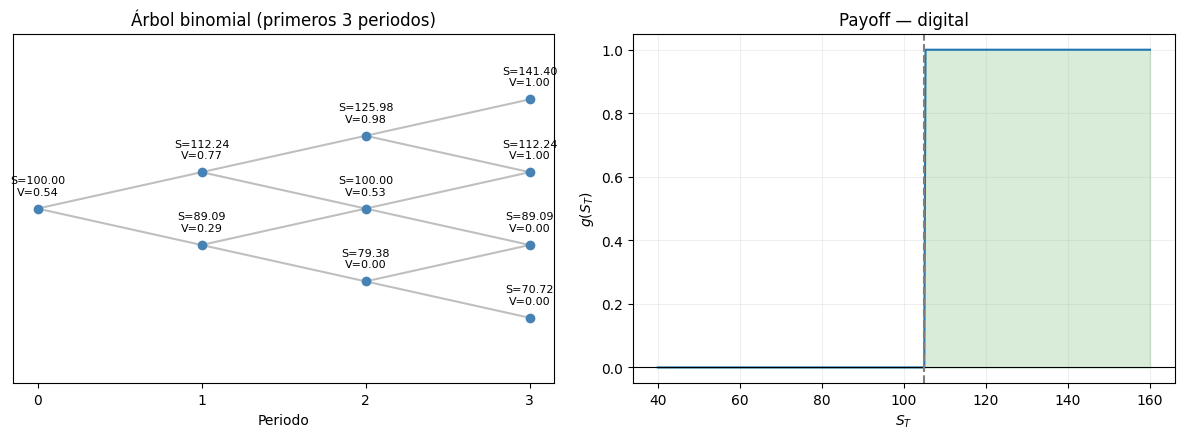

Precio por árbol: 0.537917
Precio por suma binomial: 0.537917


In [3]:

# Parámetros del modelo
S0 = 100
K = 105
T = 1
n = 3
r = 0.05
sigma = 0.20

# "call", "put", "forward", "digital"
tipo = "digital"

# Valuar y visualizar
resultado = binomial(
    S0=S0,
    K=K,
    T=T,
    n=n,
    r=r,
    sigma=sigma,
    tipo=tipo
)

mostrar_binomial(resultado)


# Martingalas y cambio de medida(Discreto)

## Representación martingala y replicación

Para un derivado europeo con payoff terminal $X$, construimos

$$
Y_i=\mathbb E^Q[B(0,T)X\mid\mathcal F_i].
$$

El proceso $Y_i$ es una $Q$-martingala.

El **Teorema de Representación Binomial** garantiza que existe una estrategia previsible $\alpha_k$ tal que

$$
\boxed{
Y_i=Y_0+\sum_{k=1}^{i}\alpha_k(Z_k-Z_{k-1})
}.
$$

Aquí, $\alpha_k$ representa las unidades del subyacente mantenidas durante el periodo $k$.

Esta representación permite construir un portafolio **autofinanciado** que replica el payoff del derivado.

Por ausencia de arbitraje, su precio es

$$
\boxed{
V_i=\frac{1}{B(0,t_i)}
\mathbb E^Q[B(0,T)X\mid\mathcal F_i]
}.
$$

En particular, al tiempo inicial:

$$
\boxed{V_0=e^{-rT}\mathbb E^Q[X]}.
$$



### Cambio de medida: Radon–Nikodym

Las medidas $P$ y $Q$ consideran las mismas trayectorias, pero les asignan probabilidades diferentes.

Suponemos $0<p,q<1$ constantes. Para una trayectoria $\omega$ de $n$ periodos, con $j$ subidas y $n-j$ bajadas:

$$
P(\omega)=p^j(1-p)^{n-j},
\qquad
Q(\omega)=q^j(1-q)^{n-j}.
$$

La **derivada de Radon–Nikodym** es el cociente entre las probabilidades de una misma trayectoria:

$$
\boxed{
\frac{dQ}{dP}(\omega)
=\frac{Q(\omega)}{P(\omega)}
=\left(\frac qp\right)^j
\left(\frac{1-q}{1-p}\right)^{n-j}
}.
$$

Este cociente modifica el peso de cada trayectoria y permite calcular esperanzas bajo $Q$ a partir de $P$:

$$
\boxed{
\mathbb E^Q[X]
=
\mathbb E^P[\frac{dQ}{dP}X]
}.
$$

Por tanto, podemos expresar el **mismo precio de no arbitraje** de dos maneras:

$$
\boxed{
V_0=e^{-rT}\mathbb E^Q[X]
=e^{-rT}\mathbb E^P[\frac{dQ}{dP}X]
}.
$$




# Modelo en tiempo continuo



En el modelo binomial valuamos mediante la esperanza neutral al riesgo descontada:

$$
V_0=e^{-rT}\mathbb E^Q[X].
$$

En tiempo continuo conservamos este principio, pero describimos el subyacente mediante ecuaciones diferenciales estocásticas.

### Movimiento browniano

Un movimiento browniano estándar $W_t$ satisface:

- $W_0=0$ y sus trayectorias son continuas.
- $W_t-W_s\sim N(0,t-s)$ para $t>s$.
- Sus incrementos son independientes de la información pasada.

Como sus trayectorias no son diferenciables, necesitamos el cálculo estocástico de Itô.

## Lema de Itô

Si

$$
dX_t=a(t,X_t)\,dt+b(t,X_t)\,dW_t,
$$

para una función suficientemente suave $f(t,x)$ se cumple

$$
\boxed{
df(t,X_t)=
\left(
\frac{\partial f}{\partial t}
+a\frac{\partial f}{\partial x}
+\frac12b^2\frac{\partial^2f}{\partial x^2}
\right)dt
+b\frac{\partial f}{\partial x}\,dW_t
}.
$$

El término adicional aparece por la variación cuadrática del movimiento browniano, que representamos formalmente como

$$
(dW_t)^2=dt.
$$

## Dinámica del subyacente bajo $P$

En el modelo de Black-Scholes suponemos

$$
\boxed{
dS_t=\mu S_t\,dt+\sigma S_t\,dW_t^P
}
$$

donde $\mu$ es el rendimiento esperado instantáneo, $\sigma>0$ es la volatilidad y $W^P$ es un movimiento browniano bajo la medida física $P$.

Para resolver la ecuación aplicamos Itô a $f(S_t)=\ln S_t$:

$$
d(\ln S_t)=
\frac{1}{S_t}dS_t
-\frac{1}{2S_t^2}(dS_t)^2.
$$

Como $(dS_t)^2=\sigma^2S_t^2dt$, obtenemos

$$
d(\ln S_t)=
\left(\mu-\frac12\sigma^2\right)dt
+\sigma\,dW_t^P.
$$

Integrando,

$$
\boxed{
S_t=S_0\exp\left[
\left(\mu-\frac12\sigma^2\right)t+\sigma W_t^P
\right]
}.
$$

## Cambio de medida: Girsanov

Queremos encontrar una medida equivalente $Q$ bajo la cual el **precio descontado** del subyacente sea una martingala.

Con tasa libre de riesgo constante $r$, definimos

$$
Z_t=e^{-rt}S_t.
$$

Aplicando la regla del producto de Itô:

$$
dZ_t=e^{-rt}S_t
\left[(\mu-r)dt+\sigma\,dW_t^P\right].
$$

Definimos el precio de mercado del riesgo

$$
\boxed{\theta=\frac{\mu-r}{\sigma}}.
$$

Por el teorema de Cameron-Martin-Girsanov, bajo las condiciones correspondientes, existe una medida $Q$ equivalente a $P$ tal que

$$
\boxed{
W_t^Q=W_t^P+\theta t
}
$$

es un movimiento browniano bajo $Q$.

Como $dW_t^P=dW_t^Q-\theta\,dt$, sustituimos en la dinámica del subyacente:

$$
dS_t=(\mu-\sigma\theta)S_t\,dt
+\sigma S_t\,dW_t^Q.
$$

Por la definición de $\theta$,

$$
\boxed{
dS_t=rS_t\,dt+\sigma S_t\,dW_t^Q
}.
$$

Así,

$$
\boxed{
d(e^{-rt}S_t)=\sigma e^{-rt}S_t\,dW_t^Q
}
$$

y el precio descontado es una martingala bajo $Q$.



### Derivada de Radon–Nikodym

El cambio de medida modifica las probabilidades asignadas a las trayectorias, sin modificar los posibles resultados.

En tiempo discreto teníamos

$$
\frac{dQ}{dP}(\omega)
=\frac{Q(\omega)}{P(\omega)}.
$$

En tiempo continuo, para un vector de observaciones $(W_{t_1},\ldots,W_{t_n})$, podemos expresar el cambio de medida como el cociente entre sus densidades conjuntas:

$$
\frac{f_Q(w_1,\ldots,w_n)}
{f_P(w_1,\ldots,w_n)}.
$$

Para observar explícitamente este cociente, consideremos el valor terminal del movimiento browniano.

Bajo $P$,

$$
W_T^P\sim N(0,T),
$$

mientras que bajo $Q$,

$$
W_T^P\sim N(-\theta T,T).
$$

Por tanto, las densidades marginales son

$$
f_P(w)=\frac{1}{\sqrt{2\pi T}}
\exp\left(-\frac{w^2}{2T}\right)
$$

y

$$
f_Q(w)=\frac{1}{\sqrt{2\pi T}}
\exp\left(-\frac{(w+\theta T)^2}{2T}\right).
$$

Calculando su cociente,

$$
\frac{f_Q(w)}{f_P(w)}
=
\exp\left(
-\frac{(w+\theta T)^2-w^2}{2T}
\right)
=
\exp\left(-\theta w-\frac12\theta^2T\right).
$$

En este modelo, dicho cociente coincide con la derivada de Radon–Nikodym sobre la información hasta $T$:

$$
\boxed{
\frac{dQ}{dP}\bigg|_{\mathcal F_T}
=
\frac{f_Q(W_T^P)}{f_P(W_T^P)}
=
\exp\left(
-\theta W_T^P-\frac12\theta^2T
\right)
}.
$$

Así, para una variable aleatoria integrable bajo $Q$,

$$
\boxed{
\mathbb E^Q[X]
=
\mathbb E^P\left[
\frac{dQ}{dP}X
\right]
}.
$$













### Distribución del subyacente bajo $Q$

Una vez obtenida la dinámica neutral al riesgo,

$$
dS_t=rS_t\,dt+\sigma S_t\,dW_t^Q,
$$

aplicamos nuevamente Itô:

$$
d(\ln S_t)=
\left(r-\frac12\sigma^2\right)dt
+\sigma\,dW_t^Q.
$$

Integrando entre $t$ y $T$, con $\tau=T-t$,

$$
\boxed{
S_T=S_t\exp\left[
\left(r-\frac12\sigma^2\right)\tau
+\sigma(W_T^Q-W_t^Q)
\right]
}.
$$

Como $W_T^Q-W_t^Q\sim N(0,\tau)$, podemos escribir

$$
\boxed{
S_T=S_t\exp\left[
\left(r-\frac12\sigma^2\right)\tau
+\sigma\sqrt{\tau}\,Z
\right],
\qquad Z\sim N(0,1)
}.
$$

Por tanto, condicionalmente a $S_t=s$,

$$
\boxed{
\ln S_T\sim
N\left(
\ln s+\left(r-\frac12\sigma^2\right)\tau,
\sigma^2\tau
\right)
}.
$$

### Valuación mediante esperanza neutral al riesgo

Para un derivado europeo con payoff $X=g(S_T)$,

$$
\boxed{
V(t,S_t)=e^{-r(T-t)}
\mathbb E^Q[g(S_T)\mid\mathcal F_t]
}.
$$

Mediante Radon–Nikodym, también podemos escribir

$$
\boxed{
V(t,S_t)=
\frac{e^{-r(T-t)}}{\Lambda_t}
\mathbb E^P[\Lambda_Tg(S_T)\mid\mathcal F_t]
}
$$

donde $\Lambda_t=(dQ/dP)|_{\mathcal F_t}$.

Utilizando la distribución de $S_T$ bajo $Q$, obtenemos la integral

$$
\boxed{
V(t,s)=e^{-r\tau}
\int_{-\infty}^{\infty}
g\left(
se^{(r-\frac12\sigma^2)\tau+\sigma\sqrt{\tau}z}
\right)
\frac{e^{-z^2/2}}{\sqrt{2\pi}}\,dz
}.
$$

Esta expresión permite calcular el precio de cualquier payoff europeo integrable que dependa únicamente de $S_T$.

### Ejemplo: call europea

Para una call,

$$
g(S_T)=(S_T-K)^+.
$$

Su precio es

$$
C(t,s)=e^{-r\tau}\mathbb E^Q[(S_T-K)^+].
$$

Sustituyendo la distribución del subyacente,

$$
C(t,s)=e^{-r\tau}
\int_{-\infty}^{\infty}
\left(se^{(r-\frac12\sigma^2)\tau+\sigma\sqrt{\tau}z}-K\right)^+
\phi(z)\,dz,
$$

donde $\phi(z)=e^{-z^2/2}/\sqrt{2\pi}$.

El payoff es positivo cuando $S_T>K$, equivalente a $z>-d_2$, donde

$$
d_2=
\frac{\ln(s/K)+(r-\frac12\sigma^2)\tau}
{\sigma\sqrt{\tau}}.
$$

Por tanto,

$$
C(t,s)=e^{-r\tau}
\left[
se^{(r-\frac12\sigma^2)\tau}
\int_{-d_2}^{\infty}e^{\sigma\sqrt{\tau}z}\phi(z)\,dz
-
K\int_{-d_2}^{\infty}\phi(z)\,dz
\right].
$$

Completando el cuadrado y utilizando la función de distribución normal acumulada $\Phi$, obtenemos

$$
\boxed{
C(t,s)=s\Phi(d_1)-Ke^{-r\tau}\Phi(d_2)
}
$$

con

$$
d_1=
\frac{\ln(s/K)+(r+\frac12\sigma^2)\tau}
{\sigma\sqrt{\tau}},
\qquad
d_2=d_1-\sigma\sqrt{\tau}.
$$

Para una put europea, por paridad put-call,

$$
\boxed{
P(t,s)=Ke^{-r\tau}\Phi(-d_2)-s\Phi(-d_1)
}.
$$



In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from IPython.display import display, Markdown


def formula_bs(s, K, T, r, sigma, tipo="call", A=1):

    s = np.asarray(s, dtype=float)
    v = sigma * np.sqrt(T)
    B = np.exp(-r*T)

    d1 = (np.log(s/K) + (r + 0.5*sigma**2)*T) / v
    d2 = d1 - v

    if tipo == "call":
        return s*norm.cdf(d1) - K*B*norm.cdf(d2)

    if tipo == "put":
        return K*B*norm.cdf(-d2) - s*norm.cdf(-d1)

    if tipo == "digital_call":
        return A*B*norm.cdf(d2)

    if tipo == "digital_put":
        return A*B*norm.cdf(-d2)

    if tipo == "forward":
        return s - K*B

    raise ValueError("Tipo de instrumento no reconocido.")


def black_scholes(S0, K, T, r, sigma, mu,
                  tipo="call", A=1):

    datos = [S0, K, T, r, sigma, mu, A]

    if not np.all(np.isfinite(datos)):
        raise ValueError("Los parámetros deben ser finitos.")

    if min(S0, K, T, sigma, A) <= 0:
        raise ValueError("S0, K, T, sigma y A deben ser positivos.")

    tipos = ["call", "put", "digital_call",
             "digital_put", "forward"]

    if tipo not in tipos:
        raise ValueError("Tipo no reconocido.")

    B = np.exp(-r*T)
    v = sigma*np.sqrt(T)
    theta = (mu-r)/sigma

    def payoff(s):
        s = np.asarray(s)

        if tipo == "call":
            return np.maximum(s-K, 0)
        if tipo == "put":
            return np.maximum(K-s, 0)
        if tipo == "digital_call":
            return A*(s>K).astype(float)
        if tipo == "digital_put":
            return A*(s<K).astype(float)
        return s-K

    # Fórmula analítica
    precio = float(formula_bs(S0, K, T, r, sigma, tipo, A))

    # Integración bajo Q y bajo P con Radon-Nikodym
    def integrar(drift, cambio_medida=False):

        centro = -theta*np.sqrt(T) if cambio_medida else 0
        limites = [centro-12, centro+12]

        zK = (np.log(K/S0) -
              (drift-0.5*sigma**2)*T) / v

        if limites[0] < zK < limites[1]:
            limites.insert(1, zK)

        def integrando(z):
            ST = S0*np.exp(
                (drift-0.5*sigma**2)*T + v*z
            )

            densidad = norm.pdf(z)

            if cambio_medida:
                Lambda = np.exp(
                    -theta*np.sqrt(T)*z
                    -0.5*theta**2*T
                )
                densidad *= Lambda

            return B*float(payoff(ST))*densidad

        return sum(
            quad(integrando, a, b,
                 epsabs=1e-10, epsrel=1e-10)[0]
            for a, b in zip(limites[:-1], limites[1:])
        )

    precio_Q = integrar(r)
    precio_P = integrar(mu, cambio_medida=True)

    if not (
        np.isclose(precio, precio_Q, atol=1e-7, rtol=1e-6)
        and np.isclose(precio, precio_P, atol=1e-7, rtol=1e-6)
    ):
        raise ArithmeticError("Las valuaciones no coinciden.")

    # Delta: cobertura inicial
    d1 = (np.log(S0/K)+(r+0.5*sigma**2)*T)/v
    d2 = d1-v

    if tipo == "call":
        delta = norm.cdf(d1)
    elif tipo == "put":
        delta = norm.cdf(d1)-1
    elif tipo == "digital_call":
        delta = A*B*norm.pdf(d2)/(S0*v)
    elif tipo == "digital_put":
        delta = -A*B*norm.pdf(d2)/(S0*v)
    else:
        delta = 1.0

    return dict(
        precio=precio,
        precio_Q=precio_Q,
        precio_P=precio_P,
        B=B,
        theta=theta,
        delta=delta,
        efectivo=precio-delta*S0,
        payoff=payoff,
        S0=S0, K=K, T=T, r=r,
        sigma=sigma, mu=mu, tipo=tipo, A=A
    )


def mostrar_black_scholes(m):

    S0 = m["S0"]
    K = m["K"]
    T = m["T"]
    r = m["r"]
    sigma = m["sigma"]
    mu = m["mu"]
    v = sigma*np.sqrt(T)

    display(Markdown(rf"""
### Black–Scholes — {m['tipo'].replace('_', ' ').capitalize()}

Bajo la medida física $P$:

$$
dS_t={mu:.4f}S_t\,dt+{sigma:.4f}S_t\,dW_t^P
$$

El cambio de medida se determina mediante

$$
\theta=\frac{{\mu-r}}{{\sigma}}
=\boxed{{{m['theta']:.6f}}}
$$

$$
\frac{{dQ}}{{dP}}
=\frac{{f_Q(W_T^P)}}{{f_P(W_T^P)}}
=e^{{-\theta W_T^P-\frac12\theta^2T}}
$$

Bajo $Q$, la dinámica es

$$
dS_t={r:.4f}S_t\,dt+{sigma:.4f}S_t\,dW_t^Q.
$$

El precio terminal sigue

$$
S_T=S_0e^{{(r-\sigma^2/2)T+\sigma\sqrt{{T}}Z}},
\qquad Z\sim N(0,1).
$$

**Valuación**

$$
\begin{{aligned}}
V_0^{{BS}} &= \boxed{{{m['precio']:.6f}}}\\[6pt]
e^{{-rT}}\mathbb E^Q[X] &= {m['precio_Q']:.6f}\\[6pt]
e^{{-rT}}\mathbb E^P\left[\frac{{dQ}}{{dP}}X\right]
&= {m['precio_P']:.6f}
\end{{aligned}}
$$

Factor de descuento:

$$
B(0,T)=e^{{-rT}}={m['B']:.6f}
$$

**Cobertura inicial**

$$
\Delta_0=\frac{{\partial V}}{{\partial S}}
={m['delta']:.6f}
$$

$$
b_0=V_0-\Delta_0S_0
={m['efectivo']:.6f}
$$

La posición inicial requiere **{abs(m['delta']):.4f} unidades**
del subyacente ({'largas' if m['delta'] >= 0 else 'cortas'}).

En la cuenta bancaria se
{'invierten' if m['efectivo'] >= 0 else 'piden prestados'}
**{abs(m['efectivo']):.4f}**.

En tiempo continuo, esta cobertura debe reajustarse dinámicamente.
"""))

    # Payoff y densidades terminales
    ST = np.linspace(
        max(0.01, min(S0, K)*0.25),
        max(S0, K)*2.5,
        600
    )

    pago = m["payoff"](ST)

    zP = (np.log(ST/S0)-(mu-0.5*sigma**2)*T)/v
    zQ = (np.log(ST/S0)-(r-0.5*sigma**2)*T)/v

    fP = norm.pdf(zP)/(ST*v)
    fQ = norm.pdf(zQ)/(ST*v)

    integrando = m["B"]*pago*fQ

    # Valor del derivado al variar el spot
    spots = np.linspace(S0*0.5, S0*1.6, 350)
    valores = formula_bs(
        spots, K, T, r, sigma, m["tipo"], m["A"]
    )

    fig, ax = plt.subplots(2, 2, figsize=(12, 8))

    # Payoff
    a = ax[0, 0]
    a.plot(ST, pago, linewidth=2, label="Payoff")
    a.fill_between(ST, 0, pago, where=pago>=0,
                   color="green", alpha=0.15)
    a.fill_between(ST, 0, pago, where=pago<0,
                   color="red", alpha=0.15)
    a.axhline(0, color="black", linewidth=0.8)
    a.axvline(K, color="gray", linestyle="--")
    a.set(title="Payoff terminal",
          xlabel="$S_T$", ylabel="$g(S_T)$")

    # Distribución bajo P y Q
    a = ax[0, 1]
    a.plot(ST, fP, label="Bajo P")
    a.plot(ST, fQ, label="Bajo Q")
    a.set(title="Distribución de $S_T$",
          xlabel="$S_T$", ylabel="Densidad")
    a.legend()

    # Integral del precio
    a = ax[1, 0]
    a.plot(ST, integrando, linewidth=2)
    a.fill_between(ST, 0, integrando,
                   where=integrando>=0,
                   color="green", alpha=0.15)
    a.fill_between(ST, 0, integrando,
                   where=integrando<0,
                   color="red", alpha=0.15)
    a.axhline(0, color="black", linewidth=0.8)
    a.set(title="Integral de valuación bajo Q",
          xlabel="$S_T$",
          ylabel="$e^{-rT}g(s)f_Q(s)$")

    # Sensibilidad al spot
    a = ax[1, 1]
    a.plot(spots, valores, linewidth=2)
    a.scatter(S0, m["precio"], zorder=3)
    a.axvline(S0, color="gray", linestyle="--")
    a.set(title="Precio del derivado vs Spot",
          xlabel="$S_0$", ylabel="$V_0$")

    for a in ax.flat:
        a.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print("Verificación: fórmula, integral Q e integral P coinciden.")


## Ejemplo


### Black–Scholes — Call

Bajo la medida física $P$:

$$
dS_t=0.1000S_t\,dt+0.2000S_t\,dW_t^P
$$

El cambio de medida se determina mediante

$$
\theta=\frac{\mu-r}{\sigma}
=\boxed{0.250000}
$$

$$
\frac{dQ}{dP}
=\frac{f_Q(W_T^P)}{f_P(W_T^P)}
=e^{-\theta W_T^P-\frac12\theta^2T}
$$

Bajo $Q$, la dinámica es

$$
dS_t=0.0500S_t\,dt+0.2000S_t\,dW_t^Q.
$$

El precio terminal sigue

$$
S_T=S_0e^{(r-\sigma^2/2)T+\sigma\sqrt{T}Z},
\qquad Z\sim N(0,1).
$$

**Valuación**

$$
\begin{aligned}
V_0^{BS} &= \boxed{8.021352}\\[6pt]
e^{-rT}\mathbb E^Q[X] &= 8.021352\\[6pt]
e^{-rT}\mathbb E^P\left[\frac{dQ}{dP}X\right]
&= 8.021352
\end{aligned}
$$

Factor de descuento:

$$
B(0,T)=e^{-rT}=0.951229
$$

**Cobertura inicial**

$$
\Delta_0=\frac{\partial V}{\partial S}
=0.542228
$$

$$
b_0=V_0-\Delta_0S_0
=-46.201481
$$

La posición inicial requiere **0.5422 unidades**
del subyacente (largas).

En la cuenta bancaria se
piden prestados
**46.2015**.

En tiempo continuo, esta cobertura debe reajustarse dinámicamente.


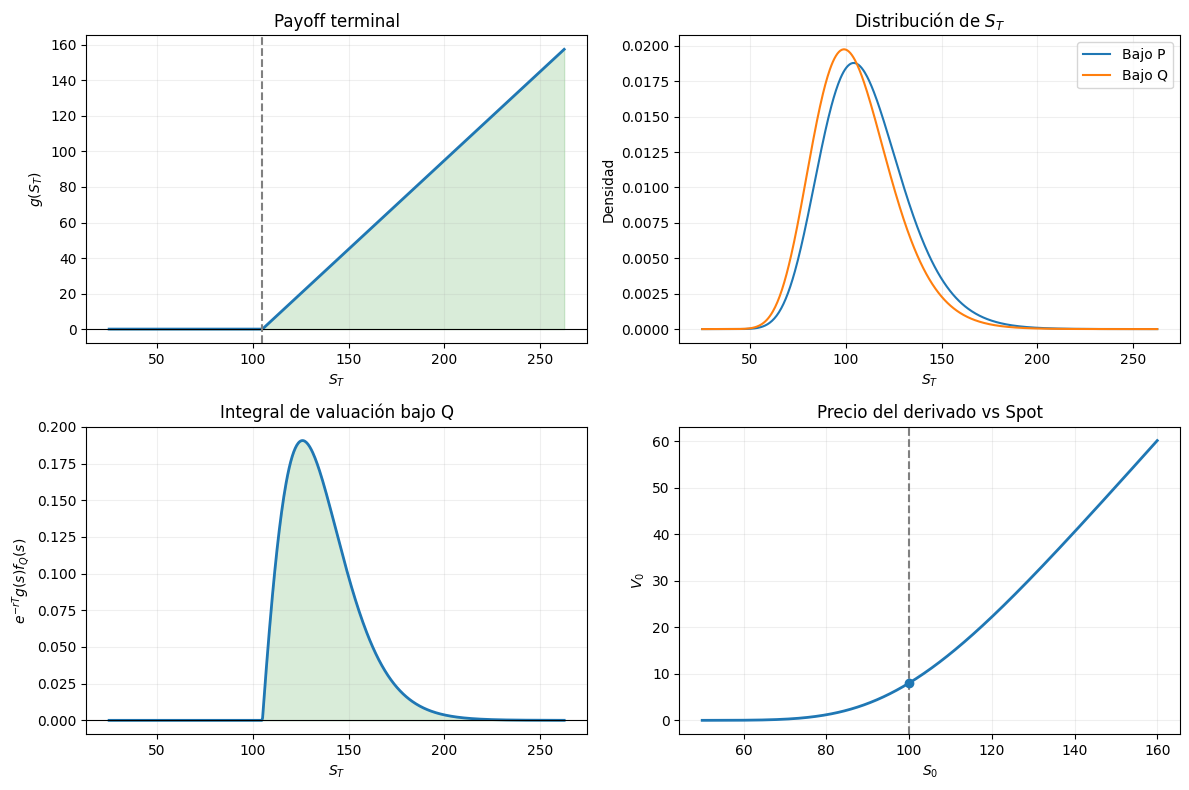

Verificación: fórmula, integral Q e integral P coinciden.


In [5]:

S0 = 100
K = 105
T = 1

r = 0.05
mu = 0.10
sigma = 0.20

# "call", "put", "digital_call", "digital_put", "forward"
tipo = "call"
A = 1  # Pago fijo de las opciones digitales

resultado = black_scholes(
    S0=S0, K=K, T=T,
    r=r, sigma=sigma, mu=mu,
    tipo=tipo, A=A
)

mostrar_black_scholes(resultado)
